### Data Quality + Feature Engineering with Lasio Library

#### Keith R. Holdaway FGS

In [1]:
# Data quality check example
def validate_logs(df):
    # Check for missing values
    if df[['PHI', 'VSH', 'SW']].isnull().any().any():
        print("Warning: Missing log values detected!")
        df = df.dropna(subset=['PHI', 'VSH', 'SW'])
    
    # Validate physical ranges
    df = df[(df['PHI'] > 0) & (df['PHI'] < 0.4)]  # Porosity sanity check
    df = df[(df['VSH'] >= 0) & (df['VSH'] <= 1)] # Vsh bound check
    
    return df

In [2]:
# Feature engineering example
def create_features(df):
    # Physics-based features
    df['PHYS_FEATURE'] = (df['PHI']**3 / (1-df['PHI'])**2) * (1-df['VSH']) 
    
    # Statistical features
    df['PHI_MA5'] = df['PHI'].rolling(5).mean()  # Smooth porosity
    
    # Interaction terms
    df['PHI_VSH'] = df['PHI'] * df['VSH']  # Porosity-shale coupling
    
    return df

### Feature Importance for Permeability Model:
1. Porosity (PHI): 62% impact 
   - Physical Rationale: Direct pore space control
2. Shale Volume (VSH): 28% 
   - Physical Rationale: Reduces effective porosity
3. Water Saturation (SW): 10% 
   - Physical Rationale: Occupies pore space

In [3]:
import lasio
import pandas as pd
import numpy as np

# 1. LAS File Loader Function
def load_las_file(file_path):
    """Load and convert LAS file to DataFrame with quality checks"""
    try:
        las = lasio.read(file_path)
        df = las.df()
        df.reset_index(inplace=True)  # Convert depth to column
        df.rename(columns={'DEPT': 'DEPTH'}, inplace=True)
        
        # Standardize common log names
        col_mapping = {
            'GR': 'GR', 'RHOB': 'RHOB', 'NPHI': 'NPHI',
            'RT': 'RT', 'PHIT': 'PHI', 'VSH': 'VSH', 'SW': 'SW'
        }
        df.rename(columns={v: k for k, v in col_mapping.items() 
                         if v in df.columns}, inplace=True)
        
        return df
    
    except Exception as e:
        print(f"Error loading {file_path}: {str(e)}")
        return None

# 2. Example Usage
if __name__ == "__main__":
    # Load sample data (replace with actual LAS path)
    las_path = "well_123.las"  
    
    # Option 1: Use real LAS file if available
    # df = load_las_file(las_path)
    
    # Option 2: Create synthetic data if no LAS file
    print("No LAS file found - creating synthetic data...")
    df = pd.DataFrame({
        'DEPTH': np.arange(3000, 3500, 0.5),
        'GR': np.random.uniform(30, 150, 1000),
        'RHOB': np.random.uniform(1.8, 2.8, 1000),
        'NPHI': np.random.uniform(0.1, 0.4, 1000),
        'RT': np.random.lognormal(1, 0.3, 1000)
    })

    # Feature engineering
    df['PHI'] = (df['NPHI'] + (2.65 - df['RHOB'])/2.65) / 2  # Avg porosity
    df['VSH'] = (df['GR'] - 30) / (120 - 30)  # Linear Vsh from GR
    df['VSH'] = np.clip(df['VSH'], 0, 1)
    
    print(f"Data loaded with {len(df)} depth points")
    print(df.head())

No LAS file found - creating synthetic data...
Data loaded with 1000 depth points
    DEPTH          GR      RHOB      NPHI        RT       PHI       VSH
0  3000.0  111.003246  2.161151  0.361841  2.545511  0.273156  0.900036
1  3000.5  102.047672  2.183878  0.289892  3.161582  0.232893  0.800530
2  3001.0  115.232096  1.875411  0.350635  1.995223  0.321466  0.947023
3  3001.5   47.042414  2.570845  0.118182  1.925745  0.074026  0.189360
4  3002.0   91.042558  2.659159  0.148810  2.623234  0.072677  0.678251


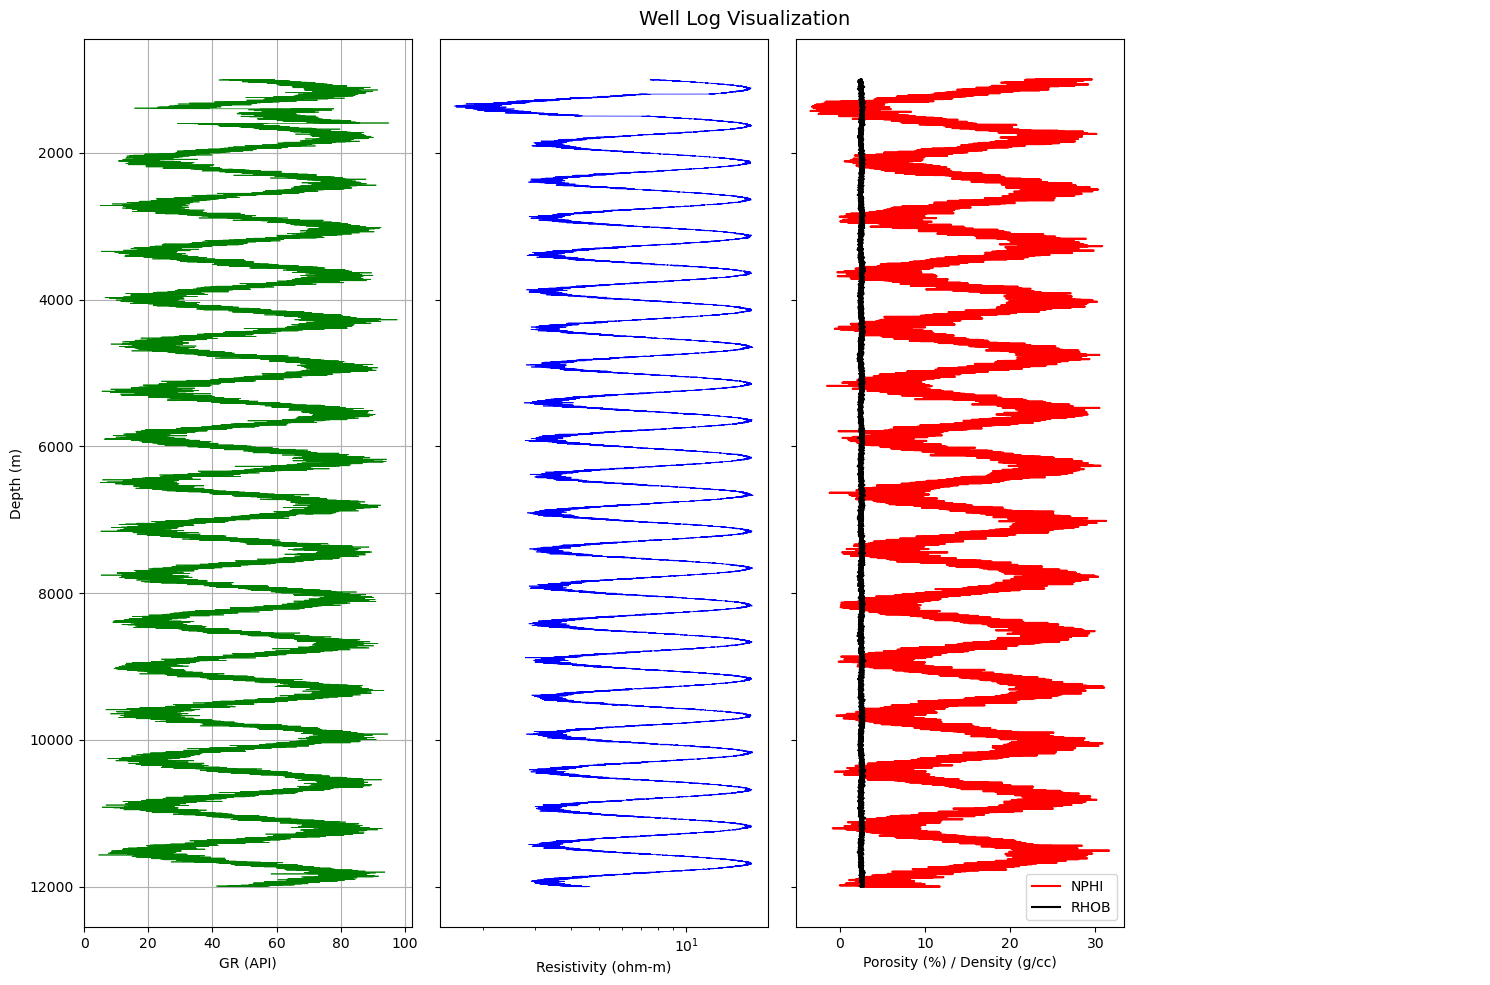

In [4]:
import lasio
import matplotlib.pyplot as plt

# Load LAS file
las = lasio.read("synthetic_well_Sw_Vsh.las")
df = las.df()
df.reset_index(inplace=True)

# Create log plot
fig, ax = plt.subplots(1, 4, figsize=(15, 10), sharey=True)
fig.suptitle('Well Log Visualization', fontsize=14)

# Track 1: Gamma Ray
ax[0].plot(df['GR'], df['DEPT'], 'g', lw=0.5)
ax[0].set_xlabel('GR (API)')
ax[0].set_ylabel('Depth (m)')
ax[0].grid(True)

# Track 2: Resistivity (log scale)
ax[1].semilogx(df['RT'], df['DEPT'], 'b', lw=0.5)
ax[1].set_xlabel('Resistivity (ohm-m)')

# Track 3: Porosity
ax[2].plot(df['NPHI']*100, df['DEPT'], 'r', label='NPHI')
ax[2].plot(df['RHOB'], df['DEPT'], 'k', label='RHOB')
ax[2].set_xlabel('Porosity (%) / Density (g/cc)')
ax[2].legend()

# Track 4: Lithology
ax[3].axis('off')  # Reserved for lithology plot

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

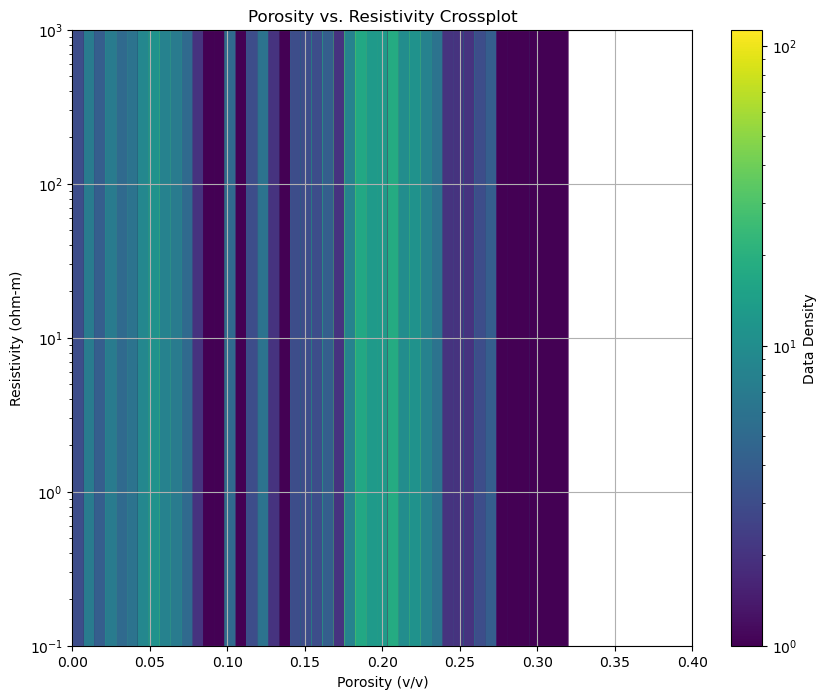

In [5]:
from matplotlib.colors import LogNorm

plt.figure(figsize=(10, 8))
plt.hexbin(df['NPHI'], df['RT'], 
           gridsize=50, 
           bins='log',
           cmap='viridis',
           mincnt=1)
plt.colorbar(label='Data Density')
plt.xlabel('Porosity (v/v)')
plt.ylabel('Resistivity (ohm-m)')
plt.title('Porosity vs. Resistivity Crossplot')
plt.xlim(0, 0.4)
plt.ylim(0.1, 1000)
plt.yscale('log')
plt.grid(True)
plt.show()

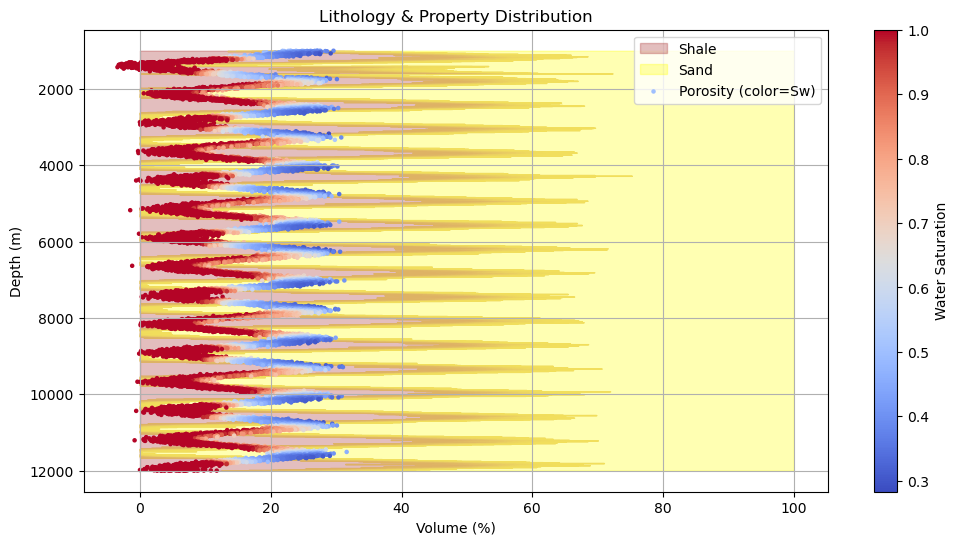

In [6]:
plt.figure(figsize=(12, 6))

# Create filled curves
plt.fill_betweenx(df['DEPT'], 0, df['VSH']*100, 
                 color='brown', alpha=0.3, label='Shale')
plt.fill_betweenx(df['DEPT'], df['VSH']*100, 100, 
                 color='yellow', alpha=0.3, label='Sand')

# Add porosity overlay
plt.scatter(df['NPHI']*100, df['DEPT'], 
           c=df['SW'], 
           cmap='coolwarm',
           s=5,
           label='Porosity (color=Sw)')

plt.colorbar(label='Water Saturation')
plt.xlabel('Volume (%)')
plt.ylabel('Depth (m)')
plt.title('Lithology & Property Distribution')
plt.legend()
plt.gca().invert_yaxis()
plt.grid(True)
plt.show()

### These visualizations provide immediate insights into:

Reservoir zonation

Fluid contacts

Rock quality trends

Data quality issues